# RQ2 mixing, sampling and Copenhagen

**Exploratory extension, not new confirmatory tests.** Only the original 896 attempts enter:
890 valid graphs (including 12 empty), six failures, **zero supplements**. The locked 24-test
family is unchanged. No paid calls or ledger queries. This notebook reads versioned aggregate
tables; no public node-level data or provider credentials are required.

[Plain-language findings](../docs/research/EXTENSION_RESULTS_20261114.md) |
[Protocol](../analysis_extension/protocol.json) | [Original RQ2 figure](05_rq2_demographic_mixing.ipynb)

The Copenhagen protocol was written after study collection, before comparison outcomes.
A raw-inventory check found 11 self-links; the recorded pre-comparison cleaning amendment
removes those only. This is **not preregistered** and not proof of held-out model training data.

**Figure release v6 (2026-11-15).** The figures displayed in this notebook are the redesigned release in `outputs/publication_figures/20261115_v6/`. They redraw the same sealed tables; no estimate, weight, endpoint or hypothesis family changed. Earlier figure releases remain unchanged in their folders. See `docs/figure_redesign/README.md`.

In [1]:
from pathlib import Path
import hashlib, json, sys, warnings
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
warnings.filterwarnings('ignore', category=DeprecationWarning)
root = Path.cwd()
if not (root/'analysis_extension').is_dir():
    root = root.parent
folder = root/'outputs/research_extension/20261114_v2'
digest = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
assert digest(folder/'manifest.json') == 'a4104ca4d67289e44767ce9390ac8b017d3657ee24a915db364da8296745dae9'
seal = json.loads((folder/'manifest.json').read_text())
assert sys.version_info[:3] == (3, 11, 9)
for name, expected in seal['artifacts'].items():
    assert digest(folder/name) == expected, name
for name, expected in seal['code_sha256'].items():
    assert digest(root/name) == expected, name
assert [seal[k] for k in ['primary_attempts','primary_valid','primary_empty','primary_failed','supplemental_graphs','paid_calls','ledger_queries']] == [896,890,12,6,0,0,0]
scores = pd.read_csv(folder/'mixing_scores.csv')
primary = pd.read_csv(root/'outputs/analysis_ready/060dcd3a86d5/primary_attempts.csv')
assert set(scores.run_id) == set(primary.original_run_id)
assert scores.groupby('run_id').size().eq(3).all()
assert scores.status.value_counts().to_dict() == {'nonempty':2634, 'empty':36, 'failed':18}
print('Sealed primary-only extension verified; original failures and empty graphs retained.')

Sealed primary-only extension verified; original failures and empty graphs retained.


## 1. RQ2: compare procedures on the same cases

Excess edge share = observed same-attribute edge fraction minus finite-roster random-pair
chance. A difference of 0.10 is ten percentage points of excess edge share, **not** ten percent
more accurate. Each procedure pair first matches model, setting and seed. We average paired
seed differences within each cell, then give the 28 cells equal weight. Missing a whole cell
suppresses the overall estimate. Empty graphs have undefined mixing scores, not zero scores.

Coleman uses roster proportions; Newman uses edge-end proportions. Different denominators
answer different questions. Newman does not remove roster or prompt-order confounding.

In [2]:
coverage = pd.read_csv(folder/'mixing_coverage.csv')
display(coverage)
contrasts = pd.read_csv(folder/'mixing_method_sensitivity.csv')
main = contrasts[contrasts.omitted_seed.eq(-1) & contrasts.score.eq('excess') & contrasts.support.eq('score_specific')]
assert main.planned_cells.eq(28).all() and main.defined_cells.eq(28).all()
display(main[['attribute','first','second','mean_difference','defined_pairs','defined_cells','planned_cells']].round(4))

,method,attribute,attempted,valid,empty,excess_defined,coleman_defined,newman_defined
0,global,gender,224,219,12,207,207,207
1,global,political orientation,224,219,12,207,207,207
2,global,religion,224,219,12,207,207,207
3,iterative,gender,224,223,0,223,223,223
4,iterative,political orientation,224,223,0,223,223,223
5,iterative,religion,224,223,0,223,223,223
6,local,gender,224,224,0,224,224,224
7,local,political orientation,224,224,0,224,224,224
8,local,religion,224,224,0,224,224,224
9,sequential,gender,224,224,0,224,224,224


,attribute,first,second,mean_difference,defined_pairs,defined_cells,planned_cells
3,gender,global,iterative,-0.1394,206,28,28
9,political orientation,global,iterative,0.1364,206,28,28
15,religion,global,iterative,-0.4062,206,28,28
21,gender,global,local,-0.1090,207,28,28
27,political orientation,global,local,0.0431,207,28,28
33,religion,global,local,-0.3110,207,28,28
39,gender,global,sequential,-0.1230,207,28,28
45,political orientation,global,sequential,0.0077,207,28,28
51,religion,global,sequential,-0.3103,207,28,28
57,gender,local,iterative,-0.0293,223,28,28


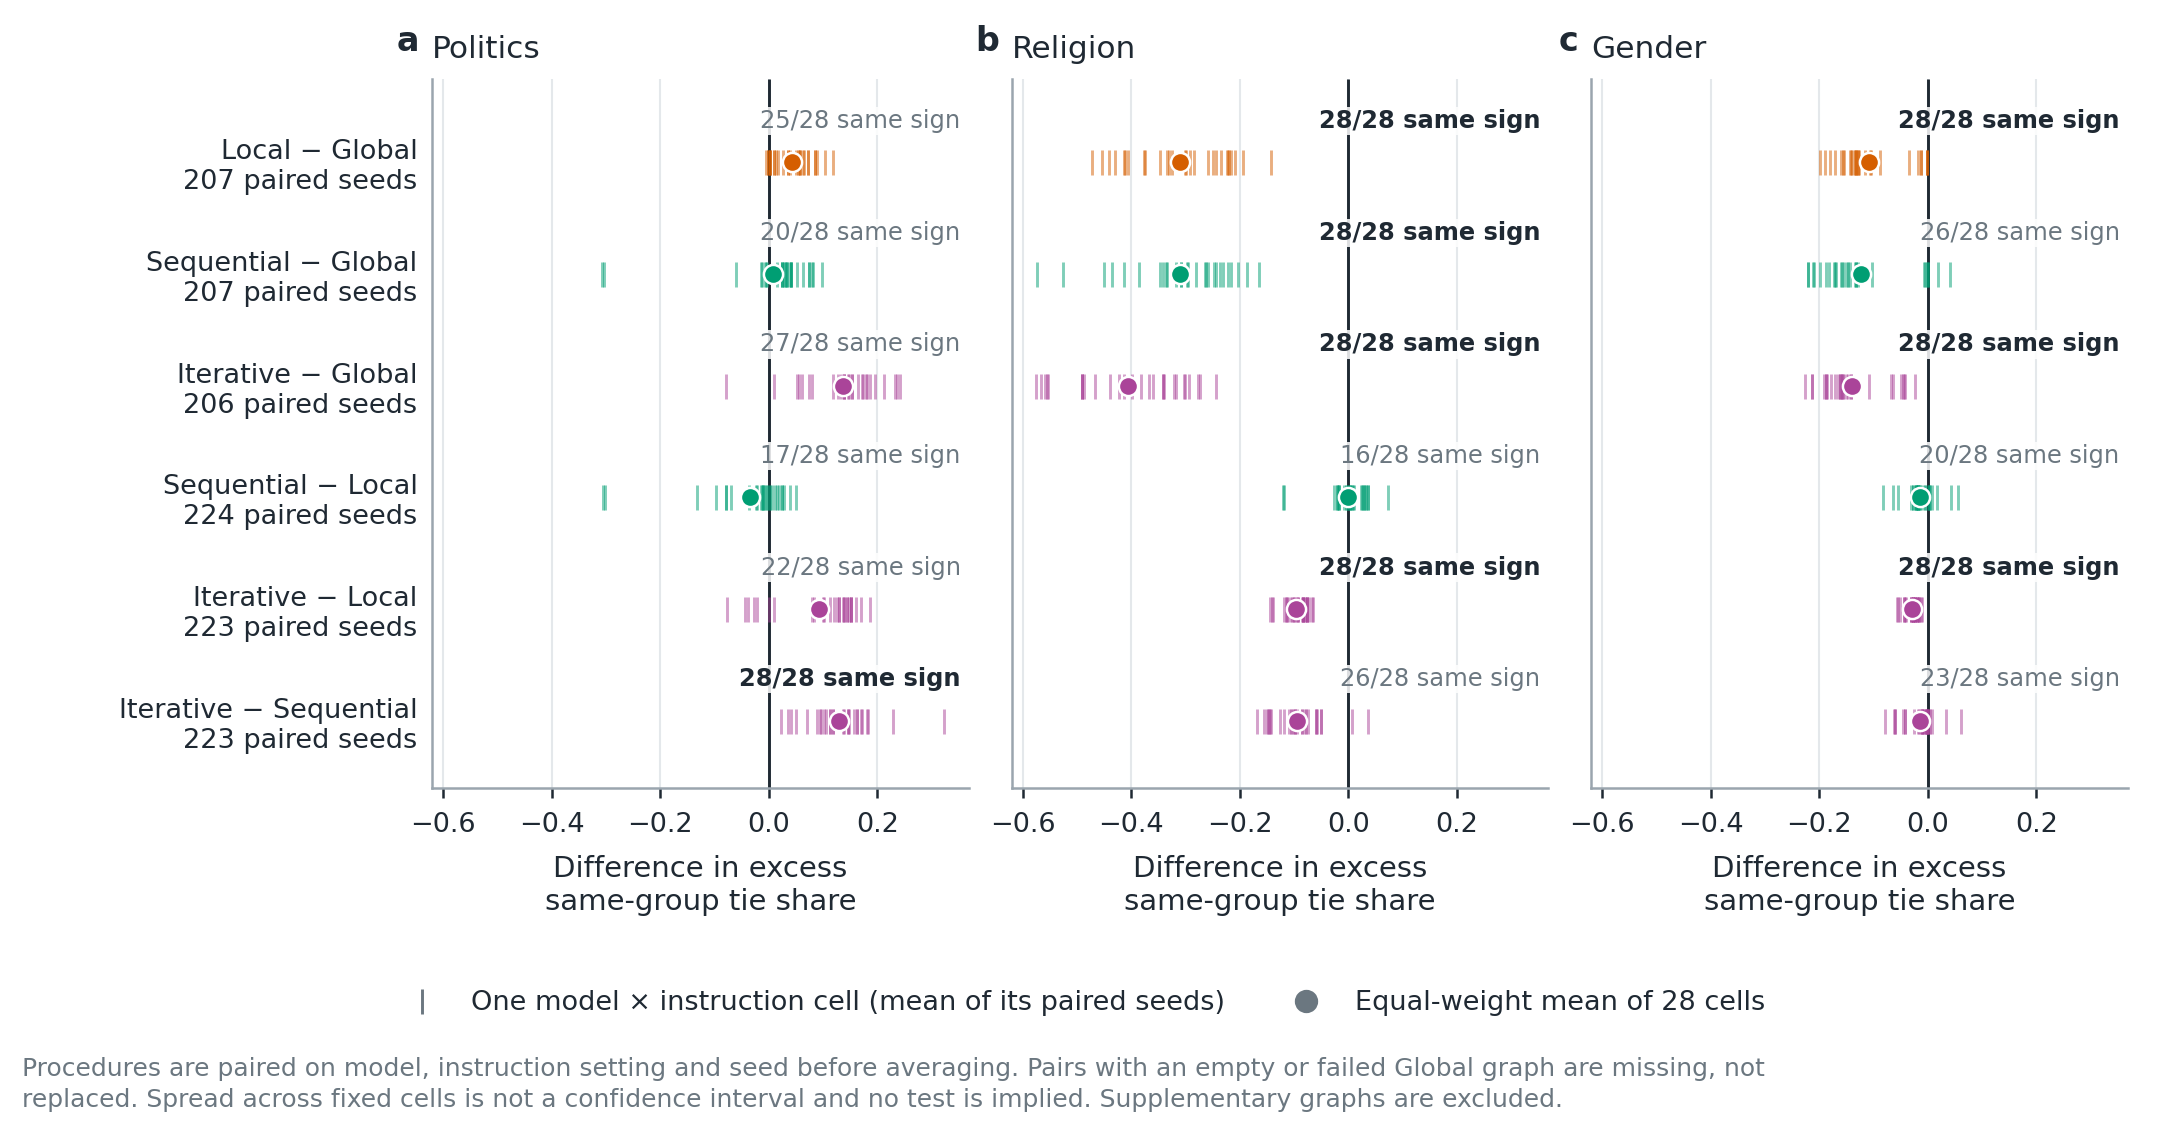

Second procedure minus first, in excess same-group tie share, paired on model, instruction setting and seed before averaging. Tick: mean paired difference in one of 28 cells. Circle: equal-weight mean of the 28 cells. The count gives how many cells share the sign of the mean. Pairs with an empty or failed graph are missing, not replaced (206 to 224 pairs). Cell spread is not a confidence interval; no new test. Primary cohort only: 896 attempts, 890 valid graphs including 12 empty, six failures; the six supplementary graphs are excluded.

In [3]:
from analysis_figures.v6.release import show
show(root, ['16_rq2_paired_mixing'])

## 2. RQ2: inspect mixing, not just attribute winners

The matrix diagonal contains within-category edges. Every undirected edge is counted in both
directions; each matrix sums to one. A large diagonal can reflect category prevalence or who
receives edges. Do not rank attributes directly from panel darkness. The scores, category
mixing and edge-end marginal shares are supplied together in the CSVs.

Rank comparisons below use the same defined seeds across attributes **and all three scores**.
Seed omission is a sensitivity check, not eight replications or a confidence interval.

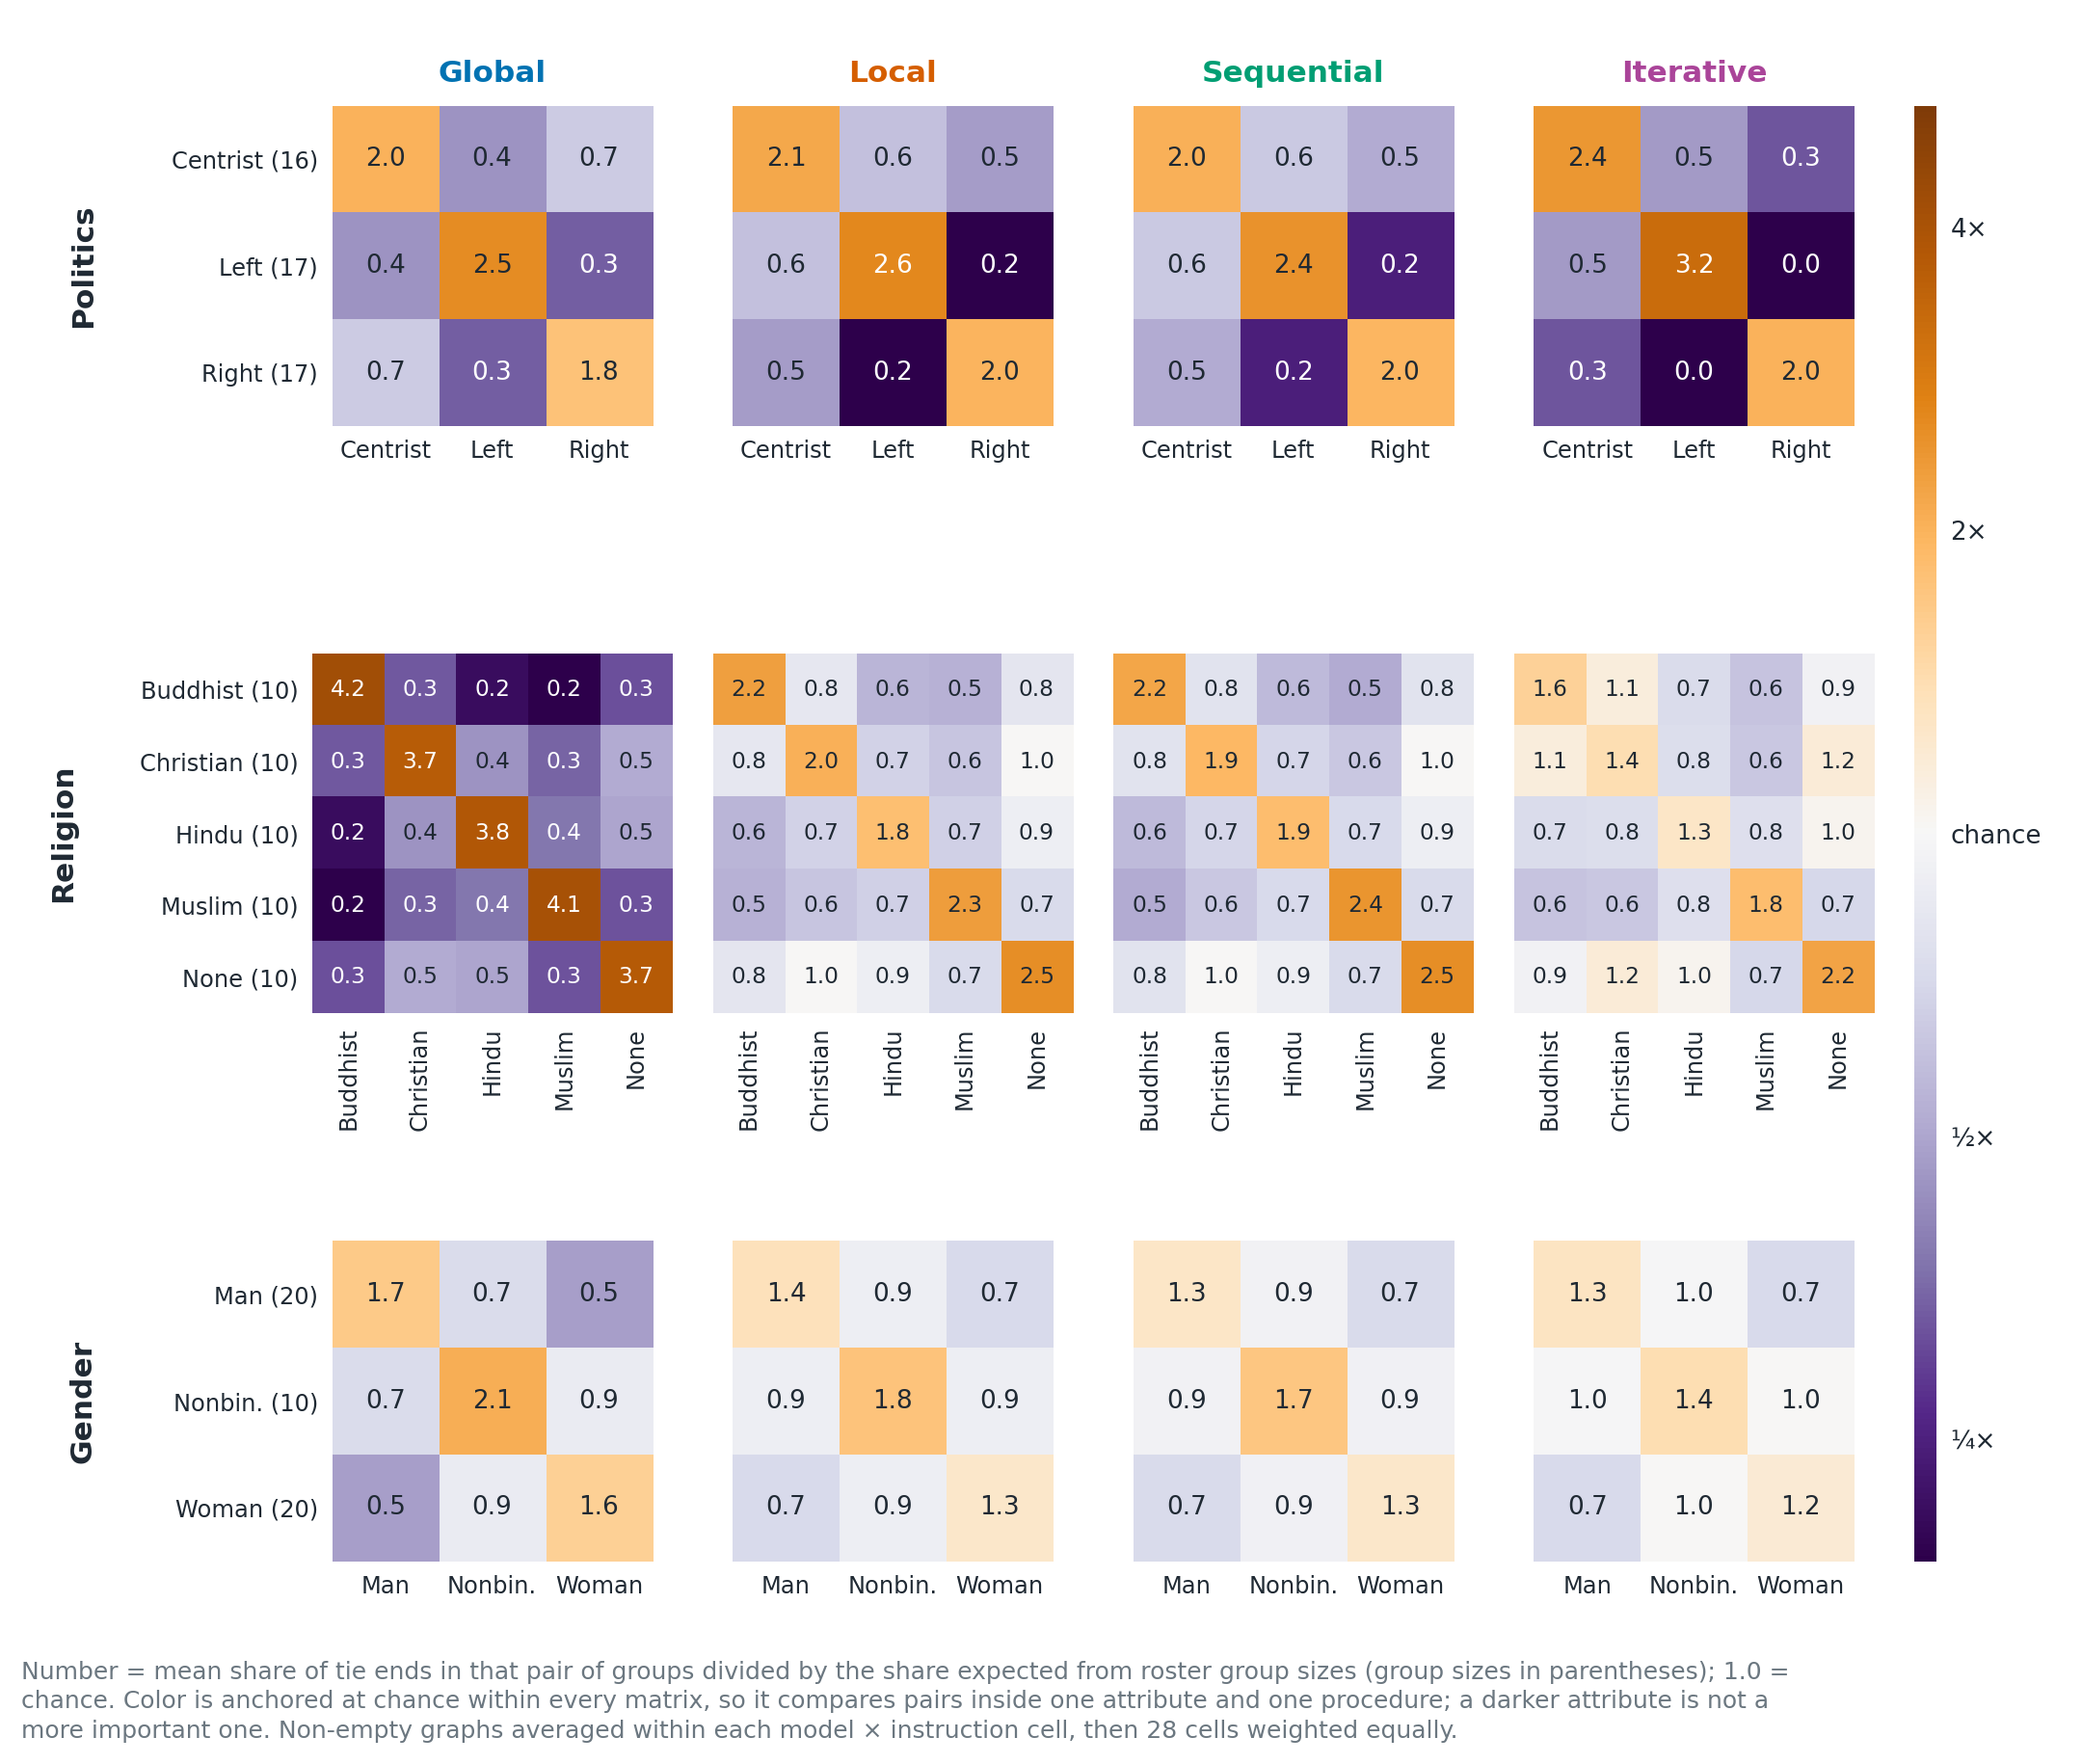

Mean share of tie ends joining each pair of groups, divided by the share expected from roster group sizes alone (group sizes in parentheses); 1.0 is chance. Each undirected tie counts in both directions. Color is centered on chance in every matrix, so it compares group pairs within one attribute and procedure; a darker attribute is not a more important attribute. Non-empty graphs averaged within cells, 28 cells weighted equally. Primary cohort only: 896 attempts, 890 valid graphs including 12 empty, six failures; the six supplementary graphs are excluded.

In [4]:
from analysis_figures.v6.release import show
show(root, ['17_rq2_mixing_matrices'])

In [5]:
ranks = pd.read_csv(folder/'mixing_rank_sensitivity.csv')
shared = ranks[ranks.support.eq('all_three_scores')]
main_ranks = shared[shared.omitted_seed.eq(-1)]
assert main_ranks.groupby(['method','score']).size().eq(28).all()
display(main_ranks.groupby(['method','score','winner']).size().rename('cells').unstack('winner',fill_value=0))
stability = shared.assign(politics_first=shared.winner.eq('political orientation')).groupby(['method','score','omitted_seed']).agg(politics_first=('politics_first','sum'),defined_cells=('winner',lambda x: x.ne('undefined').sum()))
display(stability.reset_index().query('omitted_seed != -1').groupby(['method','score']).agg(min_politics_first=('politics_first','min'),max_politics_first=('politics_first','max'),min_defined_cells=('defined_cells','min')))
common = contrasts[contrasts.omitted_seed.eq(-1) & contrasts.support.eq('all_three_scores')]
display(common[['attribute','score','first','second','mean_difference','defined_pairs','defined_cells']].round(4))

winner              political orientation  religion
method     score                                   
global     coleman                      6        22
           excess                       1        27
           newman                       6        22
iterative  coleman                     28         0
           excess                      28         0
           newman                      28         0
local      coleman                     28         0
           excess                      28         0
           newman                      28         0
sequential coleman                     28         0
           excess                      28         0
           newman                      28         0

min_politics_first  max_politics_first  min_defined_cells
method     score                                                             
global     coleman                   4                   7                 28
           excess                    0                   3                 28
           newman                    4                   9                 28
iterative  coleman                  28                  28                 28
           excess                   28                  28                 28
           newman                   28                  28                 28
local      coleman                  28                  28                 28
           excess                   28                  28                 28
           newman                   28                  28                 28
sequential coleman                  28                  28                 28
           excess                   28                  28                 28
           newman                   28                  28                 28

,attribute,score,first,second,mean_difference,defined_pairs,defined_cells
0,gender,coleman,global,iterative,-0.2274,206,28
2,gender,excess,global,iterative,-0.1394,206,28
4,gender,newman,global,iterative,-0.2202,206,28
6,political orientation,coleman,global,iterative,0.2041,206,28
8,political orientation,excess,global,iterative,0.1364,206,28
10,political orientation,newman,global,iterative,0.1994,206,28
12,religion,coleman,global,iterative,-0.5123,206,28
14,religion,excess,global,iterative,-0.4062,206,28
16,religion,newman,global,iterative,-0.5146,206,28
18,gender,coleman,global,local,-0.1803,207,28


## 3. Sampling: a small induced graph is not a scaled copy

We recompute all six metrics at 25, 40 and 50 nodes. The smaller draws are nested inside the
same 50-node draw; isolates remain. Overlap uses original public IDs before relabeling.
Full records are descriptive references, not complete population truth. Ranges below are
overlapping-draw variation, **not CIs**. Historical n=50 metrics/W1 and the older three-metric
n=25/40/50 sensitivity are reproduced to absolute tolerance 1e-12.

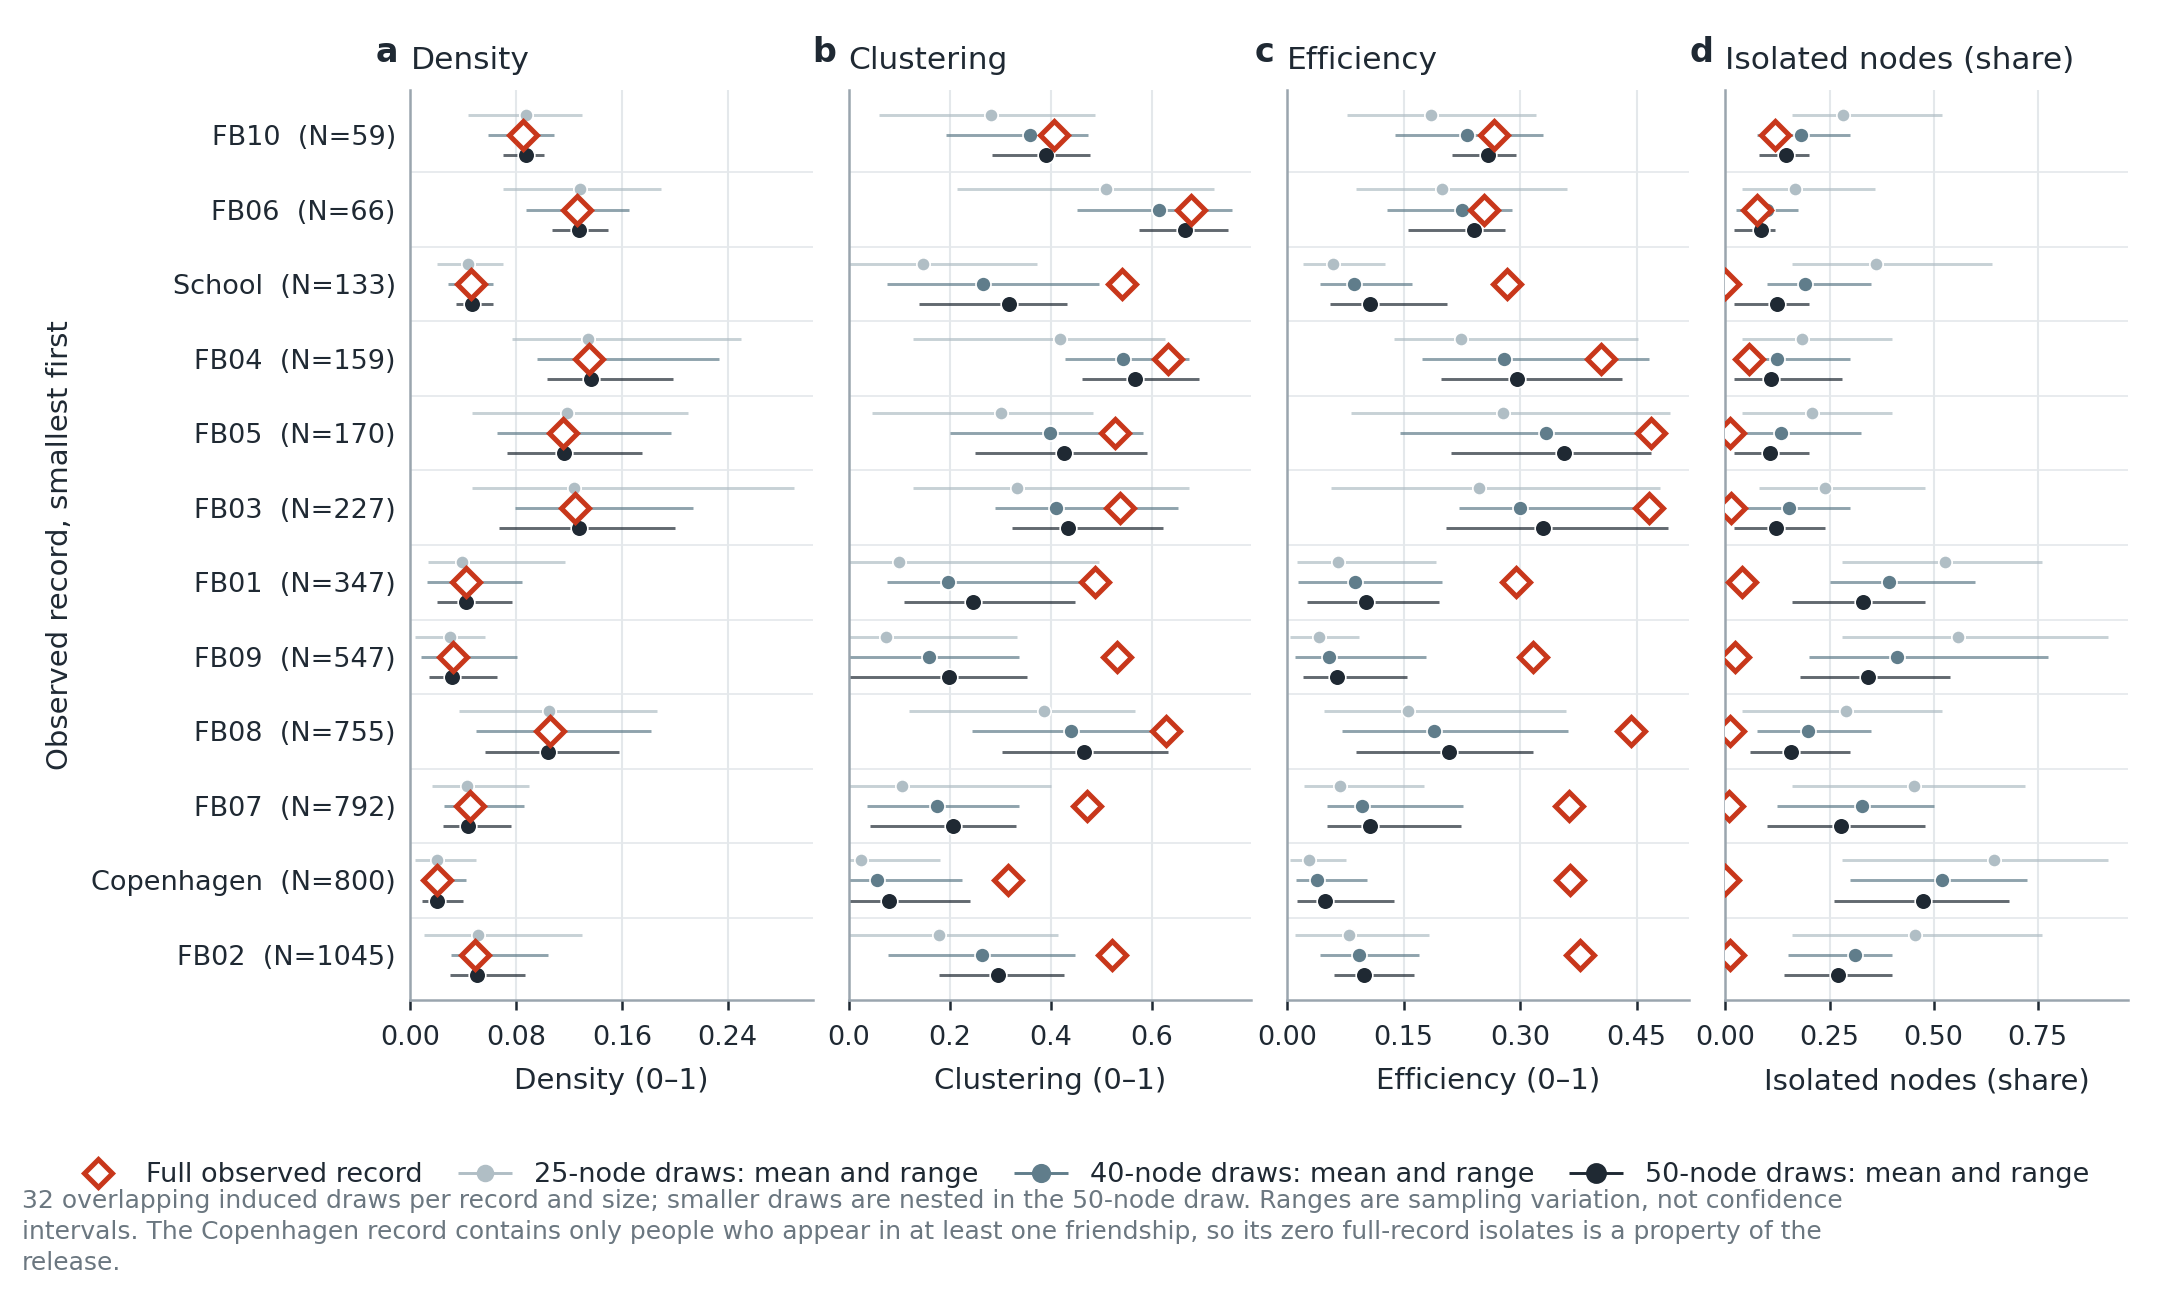

Full observed record (open diamond) against the mean and range of 32 overlapping induced draws at 25, 40 and 50 nodes, for 12 records ordered by size. Smaller draws are nested in the 50-node draw; nodes isolated by sampling are kept. Ranges are sampling variation, not confidence intervals. The Copenhagen release lists only people with at least one friendship, so its full-record isolate count of zero is a property of the release, not of the cohort. Primary cohort only: 896 attempts, 890 valid graphs including 12 empty, six failures; the six supplementary graphs are excluded.

In [6]:
from analysis_figures.v6.release import show
show(root, ['18_sampling_distortion'])

In [7]:
full = pd.read_csv(folder/'full_network_metrics.csv')
samples = pd.read_csv(folder/'observed_sample_metrics.csv')
assert len(samples) == 12*32*3
assert samples.groupby(['source','cohort','n']).size().eq(32).all()
sample_means = samples[samples.n.eq(50)].groupby(['source','cohort'])[['density','avg_clustering_coef','global_efficiency','isolates']].mean().add_prefix('sample50_')
comparison = full.merge(sample_means,on=['source','cohort'],validate='one_to_one')
display(comparison[['cohort','nodes','avg_clustering_coef','sample50_avg_clustering_coef','global_efficiency','sample50_global_efficiency','sample50_isolates']].round(4))
overlap = pd.read_csv(folder/'sample_overlap.csv')
assert len(overlap) == 12*3*496
display(overlap[overlap.n.eq(50)].groupby('cohort').shared_fraction.agg(['mean','min','max']).round(4))

,cohort,nodes,avg_clustering_coef,sample50_avg_clustering_coef,global_efficiency,sample50_global_efficiency,sample50_isolates
0,FB01,347,0.4877,0.2454,0.2951,0.1015,16.4688
1,FB02,1045,0.5209,0.2944,0.3770,0.0992,13.4688
2,FB03,227,0.5371,0.4334,0.4658,0.3290,6.0312
3,FB04,159,0.6324,0.5662,0.4035,0.2953,5.5000
4,FB05,170,0.5275,0.4259,0.4683,0.3562,5.3125
5,FB06,66,0.6777,0.6660,0.2531,0.2403,4.2188
6,FB07,792,0.4721,0.2072,0.3632,0.1062,13.8438
7,FB08,755,0.6287,0.4657,0.4431,0.2086,7.8438
8,FB09,547,0.5308,0.1982,0.3171,0.0636,17.1562
9,FB10,59,0.4069,0.3907,0.2666,0.2580,7.2188


,mean,min,max
cohort,,,
Copenhagen,0.0615,0.00,0.16
FB01,0.1419,0.02,0.34
FB02,0.0490,0.00,0.16
FB03,0.2220,0.10,0.38
FB04,0.3158,0.16,0.46
FB05,0.2964,0.14,0.48
FB06,0.7576,0.68,0.86
FB07,0.0637,0.00,0.18
FB08,0.0679,0.00,0.18


## 4. Copenhagen: one additional structural test, with a restricted roster

The versioned MIT-licensed release has 800 friendship endpoints and 6,429 raw edge records.
Eleven self-links are excluded: **800 nodes, 6,418 simple edges**, zero observed isolates.
This does not prove that unobserved people had no friends. The released gender file intersects
747 friendship endpoints; gender-only IDs are not assumed to be observed friendship isolates.
Politics/religion are unavailable, so this does **not validate RQ2 against human behavior**.

ER/BA/WS settings stay fixed from the old development panel. W1 compares valid-output
distributions, gives seven settings equal weight within each model, then averages four
model-specific distances. It is **not W1 of pooled models**. The separate target-density ER
has target information and cannot be called a fair transfer winner. All six metrics and all
three sample sizes remain available, including largest-component fraction.

In [8]:
source = json.loads((folder/'copenhagen_source.json').read_text())
assert (source['raw_edge_rows'],source['removed_self_links'],source['observed_edges'],source['observed_roster_nodes']) == (6429,11,6418,800)
assert not source['full_network_isolates_observable']
display(pd.Series({k:source[k] for k in ['doi','observed_roster_nodes','observed_edges','removed_self_links','friendship_nodes_with_gender','gender_only_ids','expected_edges_in_50','suitability']}))
transfer = pd.read_csv(folder/'transfer_record_summary.csv')
diagnostic = pd.read_csv(folder/'target_er_summary.csv')
selected = pd.concat([transfer[transfer.source.eq('copenhagen_friendship')],diagnostic],ignore_index=True)
display(selected.pivot(index=['n','kind','procedure'],columns='metric',values='mean_w1').round(4))

doi                                                10.6084/m9.figshare.7267433.v1
observed_roster_nodes                                                         800
observed_edges                                                               6418
removed_self_links                                                             11
friendship_nodes_with_gender                                                  747
gender_only_ids                                                                40
expected_edges_in_50                                                    24.599656
suitability                     endpoint-conditioned structural comparison onl...
dtype: object

metric                    avg_clustering_coef  degree_gini  density  \
n  kind       procedure                                               
25 LLM        global                   0.1002       0.3939   0.0416   
              iterative                0.5637       0.3653   0.1569   
              local                    0.4166       0.3895   0.1485   
              sequential               0.4059       0.3634   0.1497   
   baseline   BA                       0.2510       0.3921   0.1660   
              ER                       0.1526       0.4829   0.1689   
              WS                       0.3713       0.5399   0.1840   
   diagnostic target_ER                0.0224       0.0447   0.0024   
40 LLM        global                   0.1611       0.4369   0.0426   
              iterative                0.5859       0.3138   0.1545   
              local                    0.4513       0.3448   0.1479   
              sequential               0.4402       0.3146   0.1502   
   baseline   BA                       0.2420       0.3470   0.1645   
              ER                       0.1296       0.4564   0.1680   
              WS                       0.3422       0.5303   0.1838   
   diagnostic target_ER                0.0521       0.0705   0.0020   
50 LLM        global                   0.1705       0.4880   0.0422   
              iterative                0.5720       0.3033   0.1526   
              local                    0.4419       0.3386   0.1485   
              sequential               0.4364       0.3066   0.1508   
   baseline   BA                       0.2151       0.3429   0.1635   
              ER                       0.1087       0.4577   0.1685   
              WS                       0.3187       0.5477   0.1839   
   diagnostic target_ER                0.0741       0.1040   0.0025   

metric                    global_efficiency  prop_nodes_lcc  transitivity  
n  kind       procedure                                                    
25 LLM        global                 0.0925          0.2293        0.1322  
              iterative              0.2996          0.5350        0.5613  
              local                  0.4011          0.7471        0.3400  
              sequential             0.4088          0.7607        0.3351  
   baseline   BA                     0.4985          0.8238        0.2089  
              ER                     0.4992          0.8262        0.1866  
              WS                     0.4939          0.8329        0.3122  
   diagnostic target_ER              0.0043          0.0179        0.1008  
40 LLM        global                 0.1581          0.4383        0.0872  
              iterative              0.3486          0.6165        0.4878  
              local                  0.4519          0.7633        0.2607  
              sequential             0.4614          0.7645        0.2572  
   baseline   BA                     0.5209          0.7747        0.1384  
              ER                     0.5207          0.7747        0.1336  
              WS                     0.5129          0.7750        0.2294  
   diagnostic target_ER              0.0070          0.0390        0.1589  
50 LLM        global                 0.1898          0.5348        0.0658  
              iterative              0.3619          0.6131        0.4261  
              local                  0.4601          0.7206        0.1919  
              sequential             0.4699          0.7221        0.1900  
   baseline   BA                     0.5198          0.7225        0.0970  
              ER                     0.5212          0.7225        0.0974  
              WS                     0.5128          0.7225        0.1630  
   diagnostic target_ER              0.0117          0.0444        0.2206

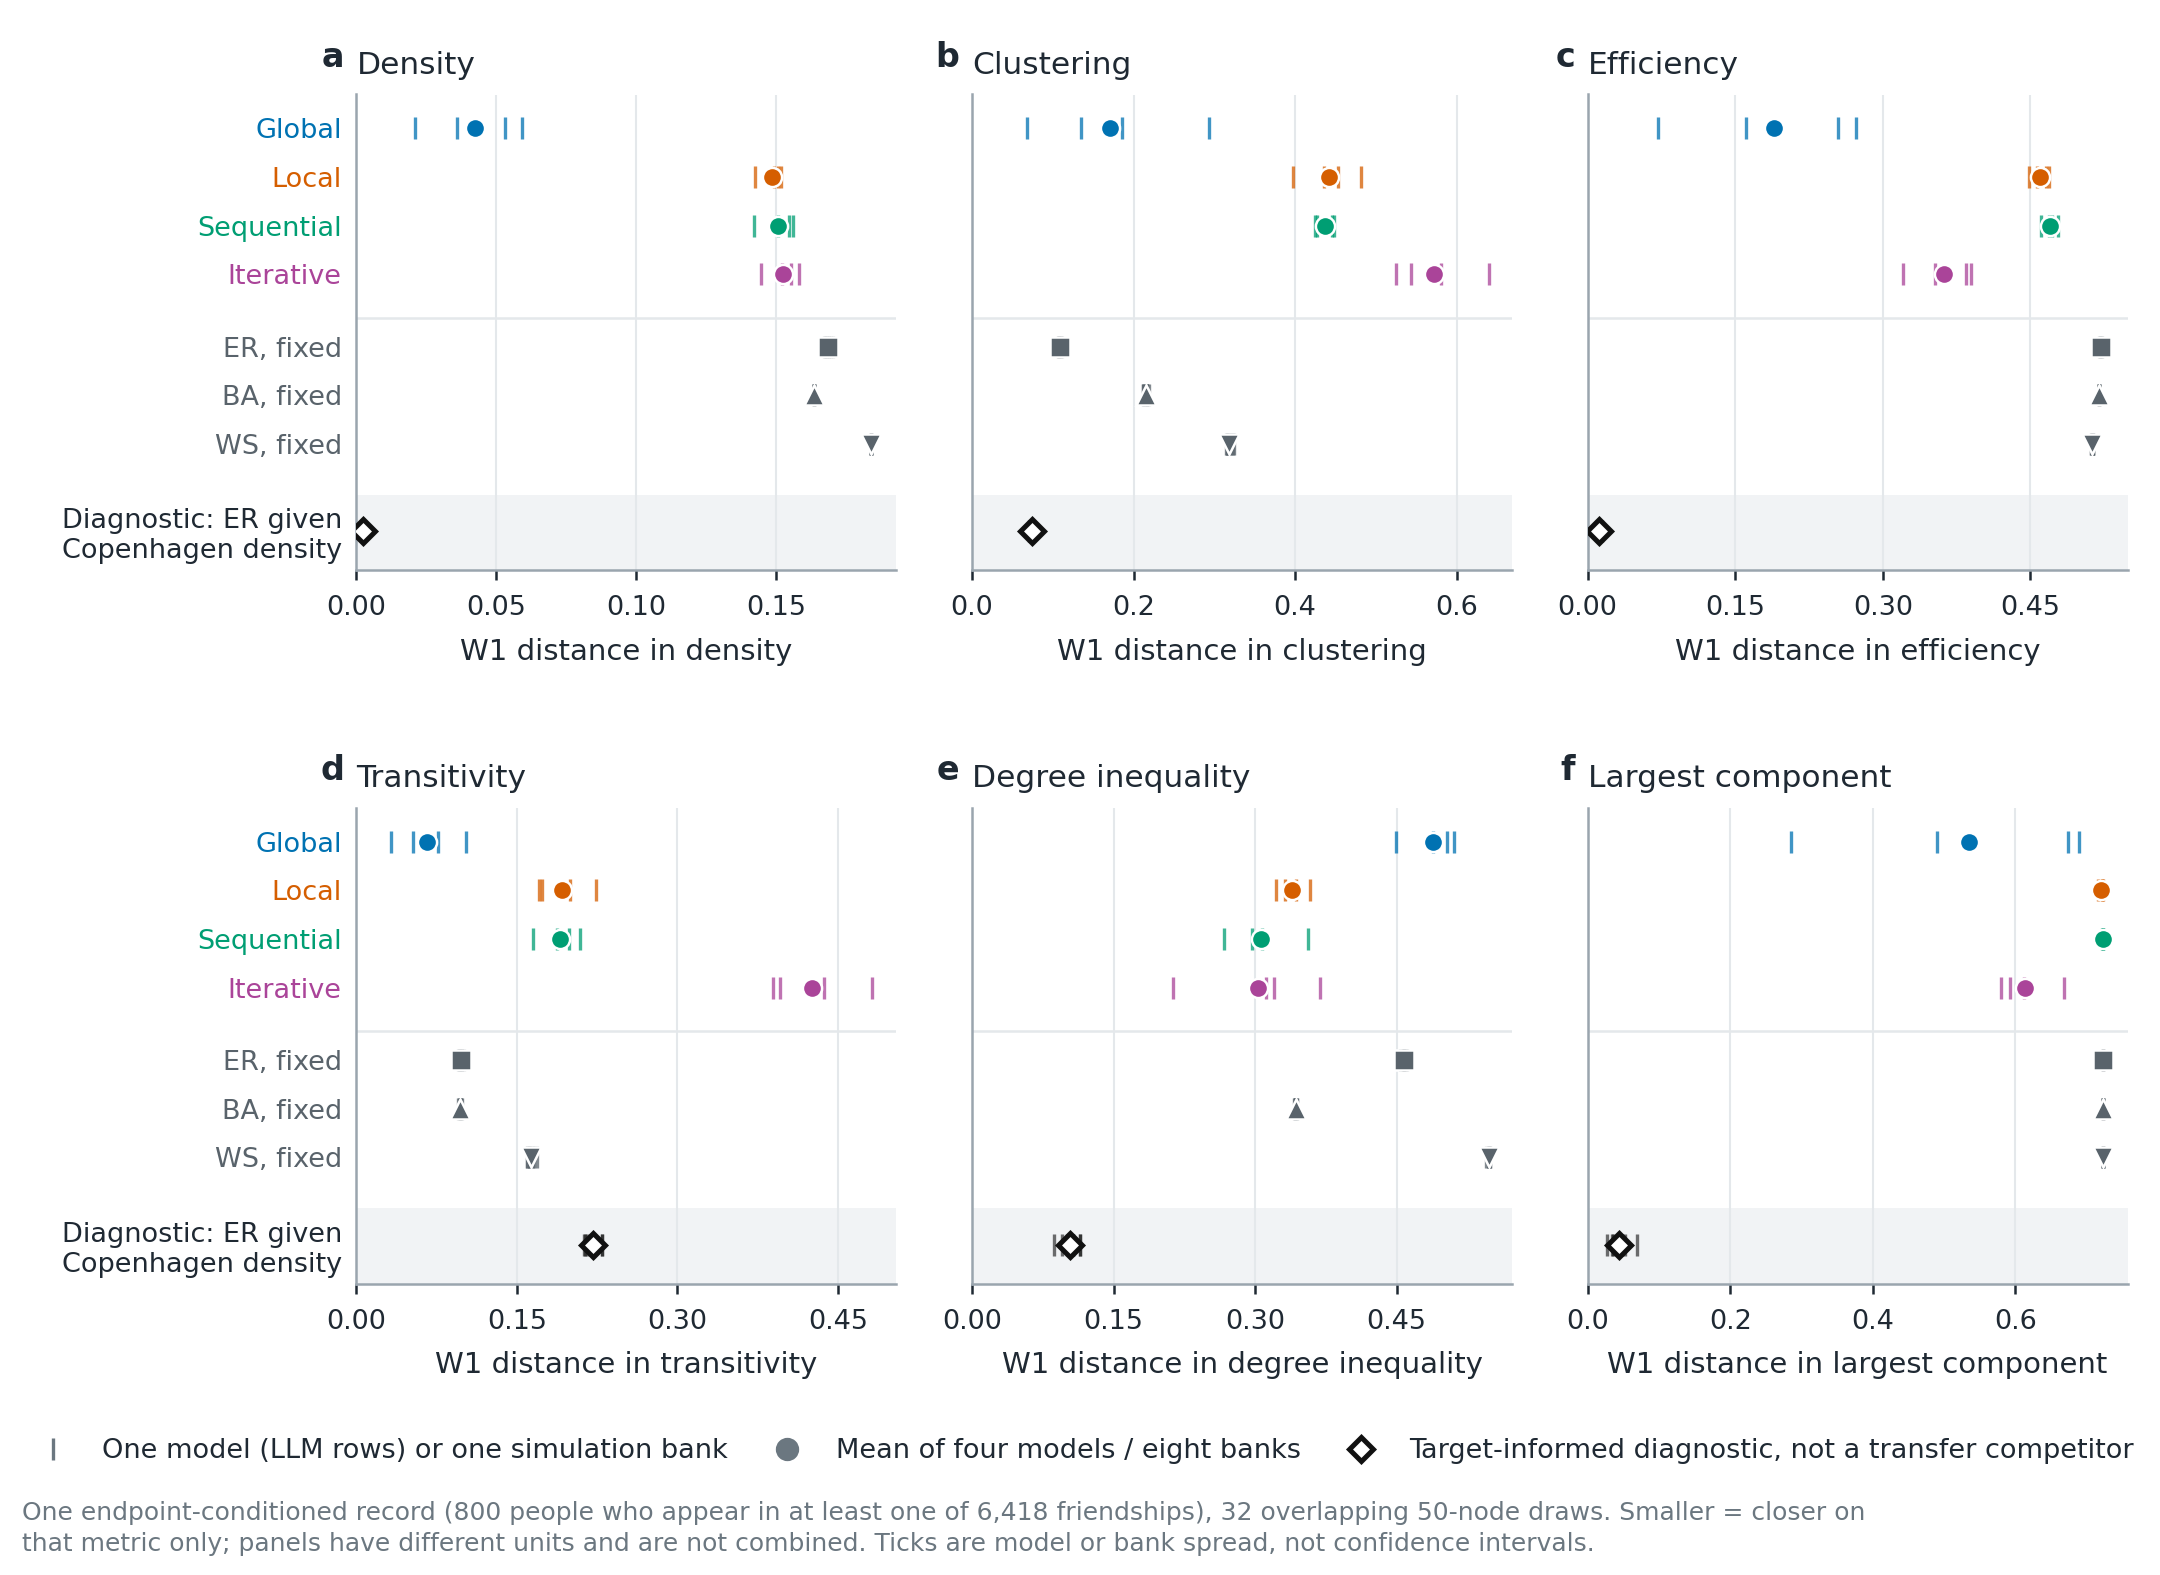

Copenhagen (800 endpoints, 6,418 friendships after removing 11 self-links from 6,429 raw rows) at 50 nodes: W1 for six metrics. Tick: one model (LLM rows) or one simulation bank. Marker: mean. The shaded bottom row is an ER graph given Copenhagen density: a target-informed diagnostic, never a transfer competitor. No procedure is closest on every metric; Global is closer than the fixed baselines on density, efficiency and transitivity, fixed ER is closer on clustering. One endpoint-conditioned record; no political or religious labels; not validation of RQ2. Primary cohort only: 896 attempts, 890 valid graphs including 12 empty, six failures; the six supplementary graphs are excluded.

In [9]:
from analysis_figures.v6.release import show
show(root, ['19_copenhagen_transfer'])

## What to say, and what not to say

- We can describe how the four procedures mix the fixed roster differently, and show whether
  the answer survives scoring and paired-support changes. We cannot infer independent causes
  or human demographic preferences from these prompts.
- We can show how induced sampling changes observed structure and candidate comparisons.
  Overlapping draws, overlapping Facebook records and one Copenhagen cohort are not many
  independent social populations.
- We can compare against Copenhagen without fitting our transfer baselines to it. A close
  W1 on one metric is not network accuracy, predictive utility or a universal ranking.
- All original failures remain visible. Six selectively completed supplements never enter.

### Method references
[Newman: Mixing patterns](https://arxiv.org/abs/cond-mat/0209450) motivates the edge-end sensitivity;
[Leskovec and Faloutsos: Sampling from Large Graphs](https://cs.stanford.edu/~jure/pubs/sampling-kdd06.pdf)
motivates explicit size/sampling checks. Neither makes our sampling representative.
[Copenhagen descriptor](https://doi.org/10.1038/s41597-019-0325-x) and
[versioned dataset](https://doi.org/10.6084/m9.figshare.7267433.v1) establish source provenance.
[Next research steps](../docs/research/NEXT_STEPS_20261114.md) relate this extension to the five
professor-supplied papers. This is AI-assisted analysis, not peer review or publication acceptance.